# Lab03 Phân tích khám phá dữ liệu

Bộ dữ liệu House Prices Advanced Regression Techniques.

# 0. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, cross_val_score

## Load Dataset

In [2]:
TRAIN_PATH = "train.csv"
TEST_PATH = "test.csv"

train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)
print(train.shape, test.shape)

(1460, 81) (1459, 80)


# 1. Giới thiệu dữ liệu

## 1.1. Thống kê nhanh biến mục tiêu

In [3]:
sp = train['SalePrice']
pd.DataFrame({'Trung bình': [sp.mean()], 'Trung vị': [sp.median()], 'Độ lệch chuẩn': [sp.std()],
              'Min': [sp.min()], 'Max': [sp.max()], 'Skewness': [sp.skew()]}).round(2)

,Trung bình,Trung vị,Độ lệch chuẩn,Min,Max,Skewness
0,180921.2,163000.0,79442.5,34900,755000,1.88


Hình 1. Phân phối SalePrice trước và sau biến đổi log1p.

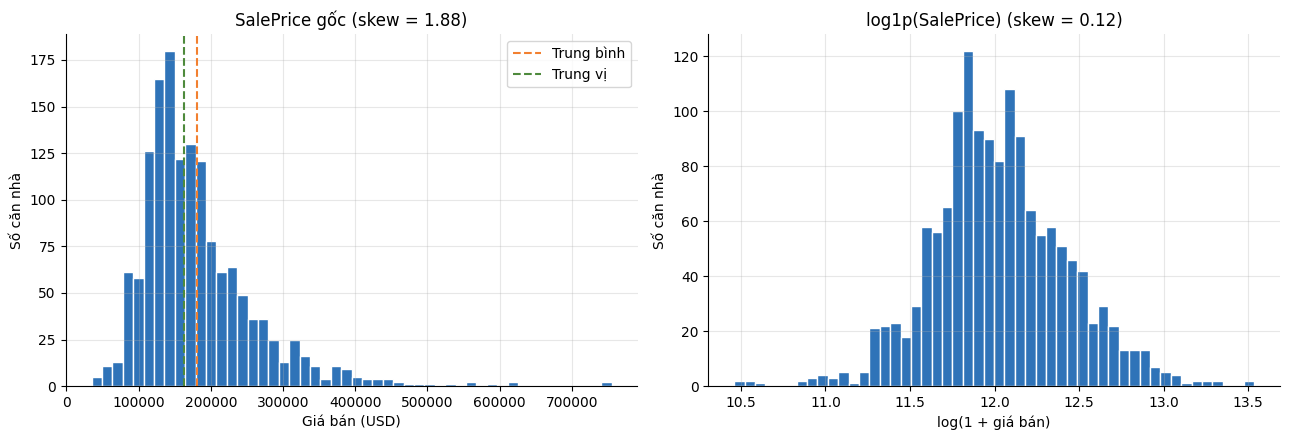

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(sp, bins=50, color='#2F73B8', edgecolor='white')
axes[0].axvline(sp.mean(), color='#F28030', linestyle='--', label='Trung bình')
axes[0].axvline(sp.median(), color='#4E8A3C', linestyle='--', label='Trung vị')
axes[0].set_title(f'SalePrice gốc (skew = {sp.skew():.2f})')
axes[0].set_xlabel('Giá bán (USD)')
axes[0].set_ylabel('Số căn nhà')
axes[0].legend()

sp_log = np.log1p(sp)
axes[1].hist(sp_log, bins=50, color='#2F73B8', edgecolor='white')
axes[1].set_title(f'log1p(SalePrice) (skew = {sp_log.skew():.2f})')
axes[1].set_xlabel('log(1 + giá bán)')
axes[1].set_ylabel('Số căn nhà')
for ax in axes:
    ax.grid(alpha=0.3)
    ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

# 2. Mô tả dữ liệu

## 2.2. Types of Data Sets

In [5]:
print("Train:", train.shape, "Test:", test.shape)
print("Số cột số:", train.select_dtypes('number').shape[1])
print("Số cột chuỗi:", train.select_dtypes(exclude='number').shape[1])
print("Số dòng trùng lặp:", train.duplicated().sum())

Train: (1460, 81) Test: (1459, 80)
Số cột số: 38
Số cột chuỗi: 43
Số dòng trùng lặp: 0


## 2.3. Chi tiết các trường dữ liệu

Tương quan với SalePrice.

In [6]:
corr_sp = train.corr(numeric_only=True)['SalePrice'].drop('SalePrice').sort_values(ascending=False)
top10 = corr_sp.head(10)
top10.round(2)

OverallQual     0.79
GrLivArea       0.71
GarageCars      0.64
GarageArea      0.62
TotalBsmtSF     0.61
1stFlrSF        0.61
FullBath        0.56
TotRmsAbvGrd    0.53
YearBuilt       0.52
YearRemodAdd    0.51
Name: SalePrice, dtype: float64

Hình 4a. Top 10 thuộc tính số tương quan mạnh nhất với SalePrice.

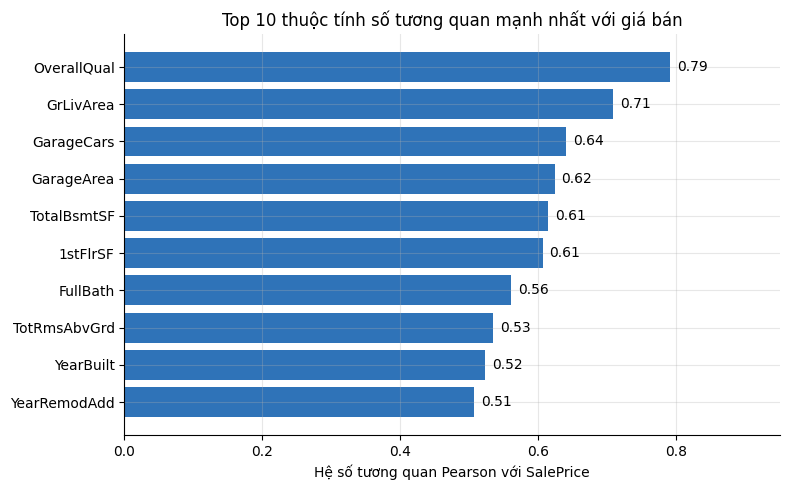

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top10.index, top10.values, color='#2F73B8')
ax.invert_yaxis()
for i, v in enumerate(top10.values):
    ax.text(v + 0.01, i, f'{v:.2f}', va='center')
ax.set_xlabel('Hệ số tương quan Pearson với SalePrice')
ax.set_title('Top 10 thuộc tính số tương quan mạnh nhất với giá bán')
ax.set_xlim(0, 0.95)
ax.grid(alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

Hình 4b. Ma trận tương quan giữa SalePrice và top 10 biến.

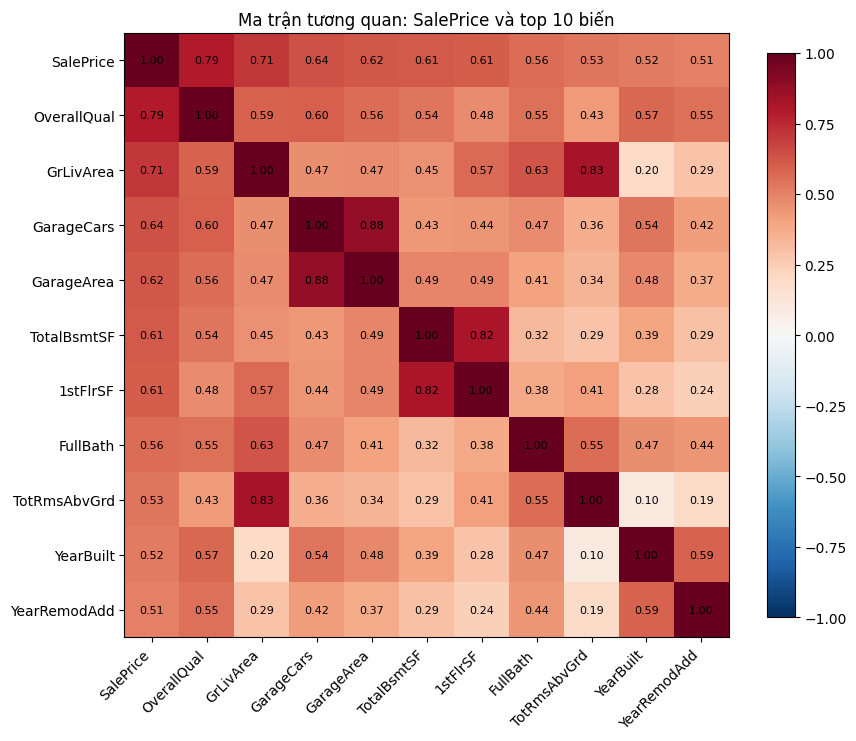

In [8]:
cols_top = ['SalePrice'] + top10.index.tolist()
corr_top = train[cols_top].corr()

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr_top, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(cols_top)))
ax.set_yticks(range(len(cols_top)))
ax.set_xticklabels(cols_top, rotation=45, ha='right')
ax.set_yticklabels(cols_top)
for i in range(len(cols_top)):
    for j in range(len(cols_top)):
        ax.text(j, i, f'{corr_top.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8)
fig.colorbar(im, shrink=0.8)
ax.set_title('Ma trận tương quan: SalePrice và top 10 biến')
plt.tight_layout()
plt.show()

Giá bán theo khu vực. Hình 5.

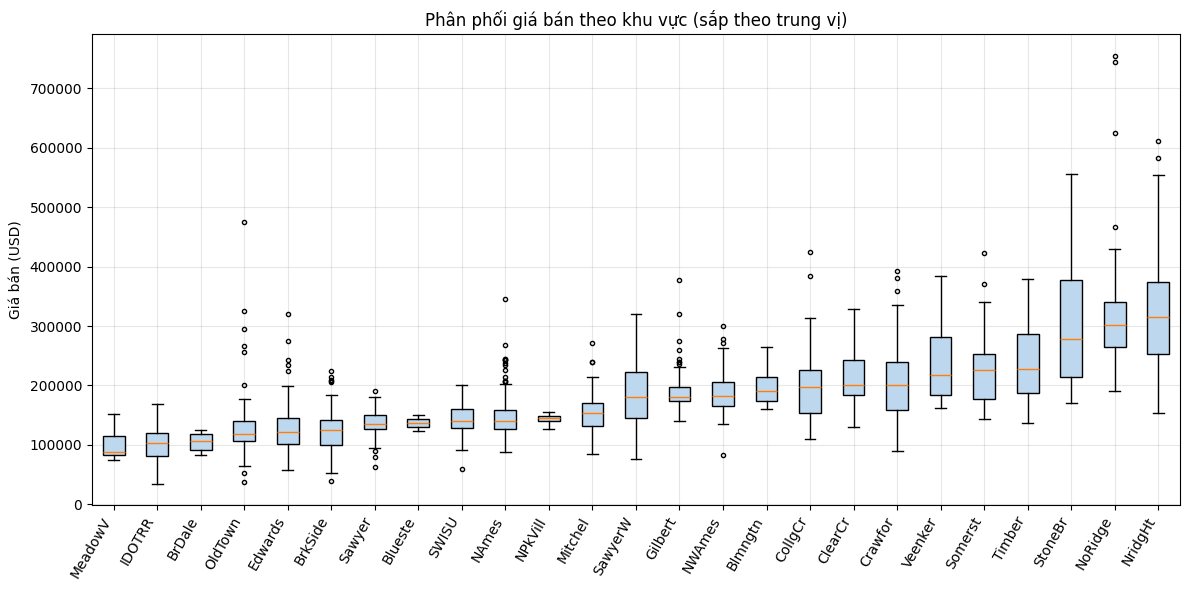

In [9]:
order = train.groupby('Neighborhood')['SalePrice'].median().sort_values().index
data = [train.loc[train['Neighborhood'] == n, 'SalePrice'] for n in order]

plt.figure(figsize=(12, 6))
plt.boxplot(data, patch_artist=True, boxprops=dict(facecolor='#BDD7EE'),
            flierprops=dict(marker='o', markersize=3))
plt.xticks(range(1, len(order) + 1), order, rotation=60, ha='right')
plt.ylabel('Giá bán (USD)')
plt.title('Phân phối giá bán theo khu vực (sắp theo trung vị)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Giá trị thiếu. Hình 3.

In [10]:
missing = train.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing_pct = missing / len(train) * 100
print("Số cột thiếu ở train:", len(missing))
print("Số cột thiếu ở test:", (test.isnull().sum() > 0).sum())
print("Tổng số ô thiếu ở train:", missing.sum())
missing_pct.round(1)

Số cột thiếu ở train: 19
Số cột thiếu ở test: 33
Tổng số ô thiếu ở train: 7829


PoolQC          99.5
MiscFeature     96.3
Alley           93.8
Fence           80.8
MasVnrType      59.7
FireplaceQu     47.3
LotFrontage     17.7
GarageType       5.5
GarageYrBlt      5.5
GarageFinish     5.5
GarageQual       5.5
GarageCond       5.5
BsmtExposure     2.6
BsmtFinType2     2.6
BsmtQual         2.5
BsmtCond         2.5
BsmtFinType1     2.5
MasVnrArea       0.5
Electrical       0.1
dtype: float64

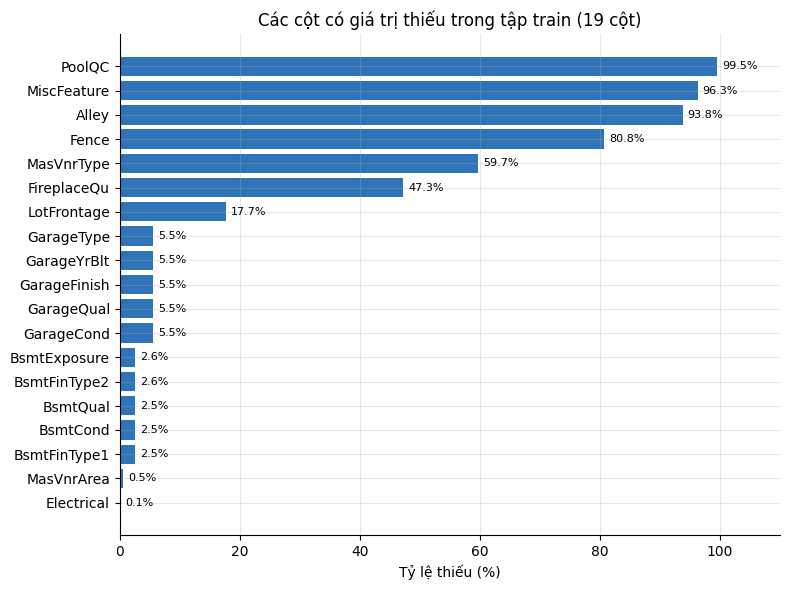

In [11]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(missing_pct.index, missing_pct.values, color='#2F73B8')
ax.invert_yaxis()
for i, v in enumerate(missing_pct.values):
    ax.text(v + 0.8, i, f'{v:.1f}%', va='center', fontsize=8)
ax.set_xlim(0, 110)
ax.set_xlabel('Tỷ lệ thiếu (%)')
ax.set_title(f'Các cột có giá trị thiếu trong tập train ({len(missing)} cột)')
ax.grid(alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

## 2.4. Phân loại dữ liệu

In [12]:
continuous = ['LotFrontage', 'LotArea', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF',
              '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF',
              'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal']
discrete = ['BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr',
            'TotRmsAbvGrd', 'Fireplaces', 'GarageCars']
time_vars = ['YearBuilt', 'YearRemodAdd', 'GarageYrBlt', 'MoSold', 'YrSold']
ordinal_num = ['OverallQual', 'OverallCond']
nominal = ['MSSubClass', 'MSZoning', 'Alley', 'LandContour', 'LotConfig', 'Neighborhood', 'Condition1',
           'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd',
           'MasVnrType', 'Foundation', 'Heating', 'Electrical', 'GarageType', 'MiscFeature', 'SaleType',
           'SaleCondition']
ordinal_cat = ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
               'HeatingQC', 'KitchenQual', 'FireplaceQu', 'GarageFinish', 'GarageQual', 'GarageCond', 'PoolQC',
               'Fence', 'LotShape', 'LandSlope', 'Functional', 'PavedDrive', 'Utilities']
binary = ['Street', 'CentralAir']

groups = {'Liên tục': continuous, 'Rời rạc (đếm)': discrete, 'Thời gian': time_vars, 'Thứ tự (số)': ordinal_num,
          'Danh nghĩa': nominal, 'Thứ tự (chữ)': ordinal_cat, 'Nhị phân': binary}
counts = {k: len(v) for k, v in groups.items()}
print(counts)
print("Định lượng:", sum(counts[k] for k in list(counts)[:4]), "Định tính:", sum(counts[k] for k in list(counts)[4:]))

{'Liên tục': 19, 'Rời rạc (đếm)': 9, 'Thời gian': 5, 'Thứ tự (số)': 2, 'Danh nghĩa': 22, 'Thứ tự (chữ)': 20, 'Nhị phân': 2}
Định lượng: 35 Định tính: 44


Hình 2. Số lượng biến theo từng loại.

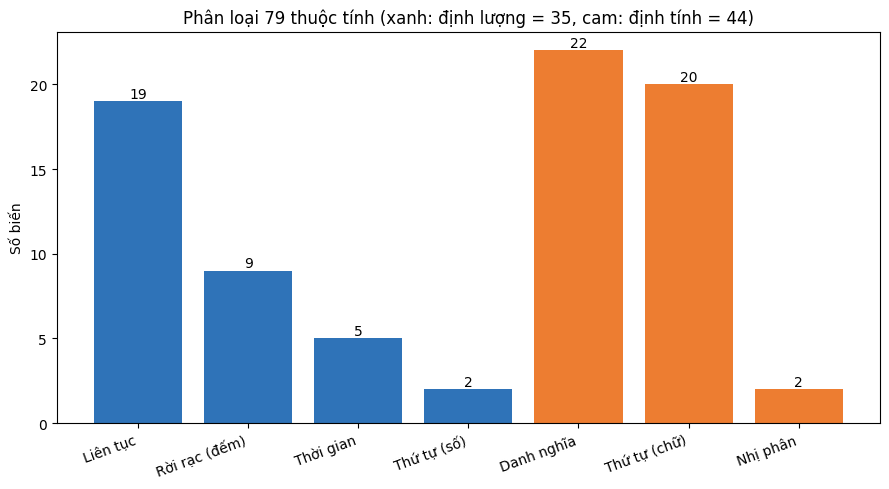

In [13]:
fig, ax = plt.subplots(figsize=(9, 5))
colors = ['#2F73B8'] * 4 + ['#ED7D31'] * 3
bars = ax.bar(counts.keys(), counts.values(), color=colors)
for b in bars:
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.2, int(b.get_height()), ha='center')
ax.set_ylabel('Số biến')
ax.set_title('Phân loại 79 thuộc tính (xanh: định lượng = 35, cam: định tính = 44)')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

# 3. ĐÁNH GIÁ CHẤT LƯỢNG DỮ LIỆU

## 3.1. Missing values

In [14]:
print("Tổng số ô thiếu ở train:", train.isnull().sum().sum())
print("Số cột có dữ liệu thiếu ở train:", (train.isnull().sum() > 0).sum())
print("Số cột có dữ liệu thiếu ở test:", (test.isnull().sum() > 0).sum())

Tổng số ô thiếu ở train: 7829
Số cột có dữ liệu thiếu ở train: 19
Số cột có dữ liệu thiếu ở test: 33


## 3.2. Duplicate

In [15]:
print("Số dòng trùng lặp ở train:", train.duplicated().sum())

Số dòng trùng lặp ở train: 0


## 3.3. Invalid values

In [16]:
print("Số giá trị âm:", (train.select_dtypes('number') < 0).sum().sum())
print("Số dòng GrLivArea không khớp tổng các tầng:",
      (train['GrLivArea'] != train['1stFlrSF'] + train['2ndFlrSF'] + train['LowQualFinSF']).sum())

Số giá trị âm: 0
Số dòng GrLivArea không khớp tổng các tầng: 0


## 3.4. Inconsistent data

In [17]:
print("GarageYrBlt > YrSold:", (train['GarageYrBlt'] > train['YrSold']).sum())
print("YearRemodAdd < YearBuilt:", (train['YearRemodAdd'] < train['YearBuilt']).sum())
print("YrSold < YearBuilt:", (train['YrSold'] < train['YearBuilt']).sum())
print("YrSold < YearRemodAdd:", (train['YrSold'] < train['YearRemodAdd']).sum())

GarageYrBlt > YrSold: 0
YearRemodAdd < YearBuilt: 0
YrSold < YearBuilt: 0
YrSold < YearRemodAdd: 1


## 3.5. Outlier sơ bộ

In [18]:
for col in ['SalePrice', 'GrLivArea', 'LotArea', 'TotalBsmtSF', '1stFlrSF', 'GarageArea']:
    q1, q3 = train[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((train[col] < q1 - 1.5 * iqr) | (train[col] > q3 + 1.5 * iqr)).sum()
    print(col, n_out)

SalePrice 61
GrLivArea 31
LotArea 69
TotalBsmtSF 61
1stFlrSF 20
GarageArea 21


# 4. EDA

## 4.1. Univariate Analysis

Thống kê mô tả.

In [19]:
features = ['OverallQual', 'YearBuilt', 'LotArea', 'TotalBsmtSF', 'GrLivArea', 'GarageArea', 'SalePrice']
q1 = train[features].quantile(0.25)
q3 = train[features].quantile(0.75)
desc = pd.DataFrame({'Mean': train[features].mean(), 'Median': train[features].median(),
                     'Std': train[features].std(), 'Min': train[features].min(),
                     'Q1': q1, 'Q3': q3, 'Max': train[features].max(), 'IQR': q3 - q1})
desc.round(2)

,Mean,Median,Std,Min,Q1,Q3,Max,IQR
OverallQual,6.10,6.0,1.38,1,5.00,7.00,10,2.00
YearBuilt,1971.27,1973.0,30.20,1872,1954.00,2000.00,2010,46.00
LotArea,10516.83,9478.5,9981.26,1300,7553.50,11601.50,215245,4048.00
TotalBsmtSF,1057.43,991.5,438.71,0,795.75,1298.25,6110,502.50
GrLivArea,1515.46,1464.0,525.48,334,1129.50,1776.75,5642,647.25
GarageArea,472.98,480.0,213.80,0,334.50,576.00,1418,241.50
SalePrice,180921.20,163000.0,79442.50,34900,129975.00,214000.00,755000,84025.00


Histogram.

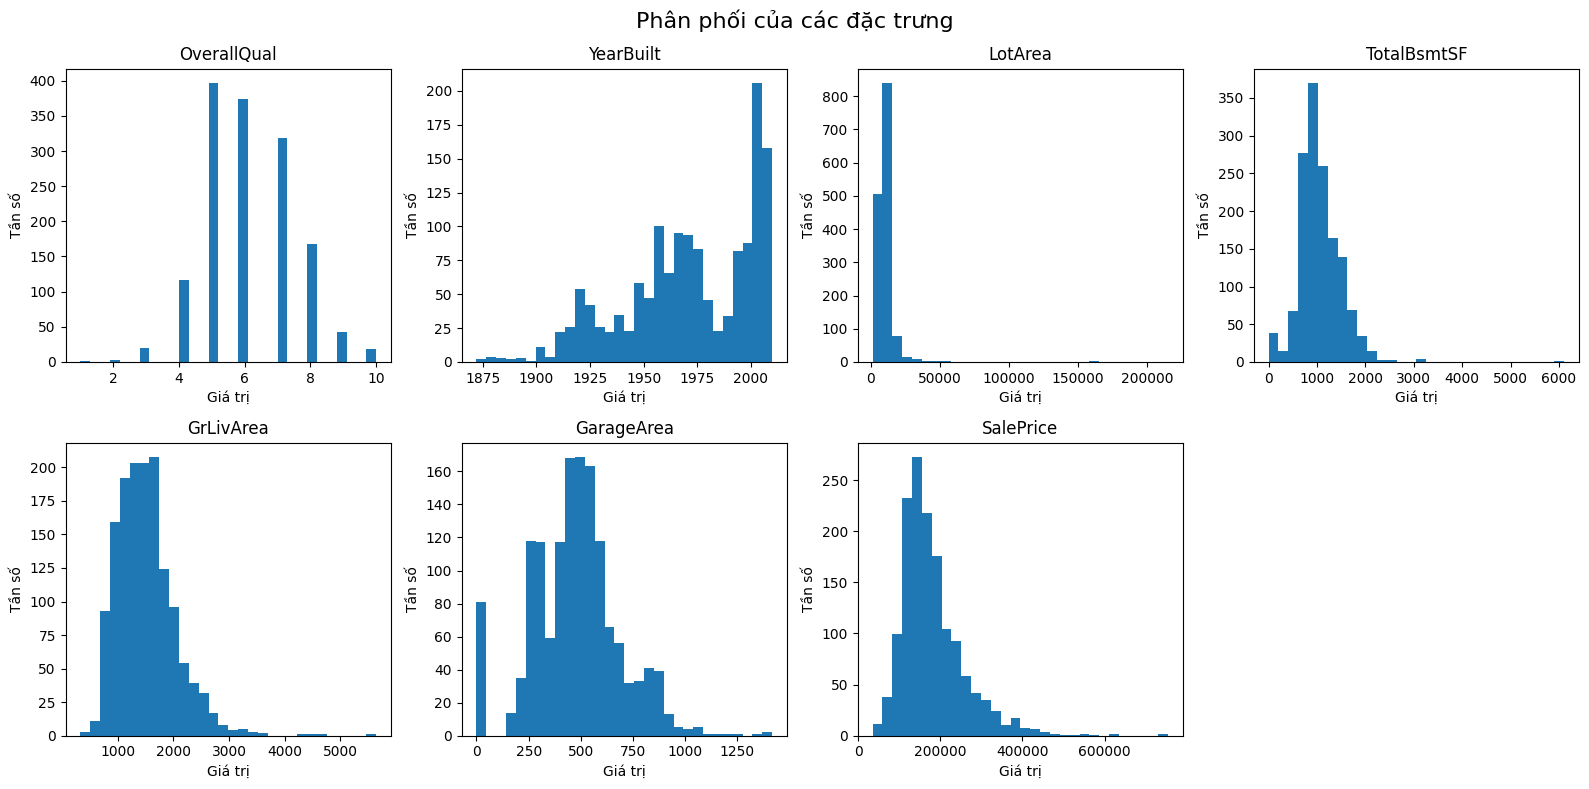

In [20]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()
for ax, col in zip(axes, features):
    ax.hist(train[col], bins=30)
    ax.set_title(col)
    ax.set_xlabel('Giá trị')
    ax.set_ylabel('Tần số')
axes[-1].axis('off')
fig.suptitle('Phân phối của các đặc trưng', fontsize=16)
plt.tight_layout()
plt.show()

Boxplot.

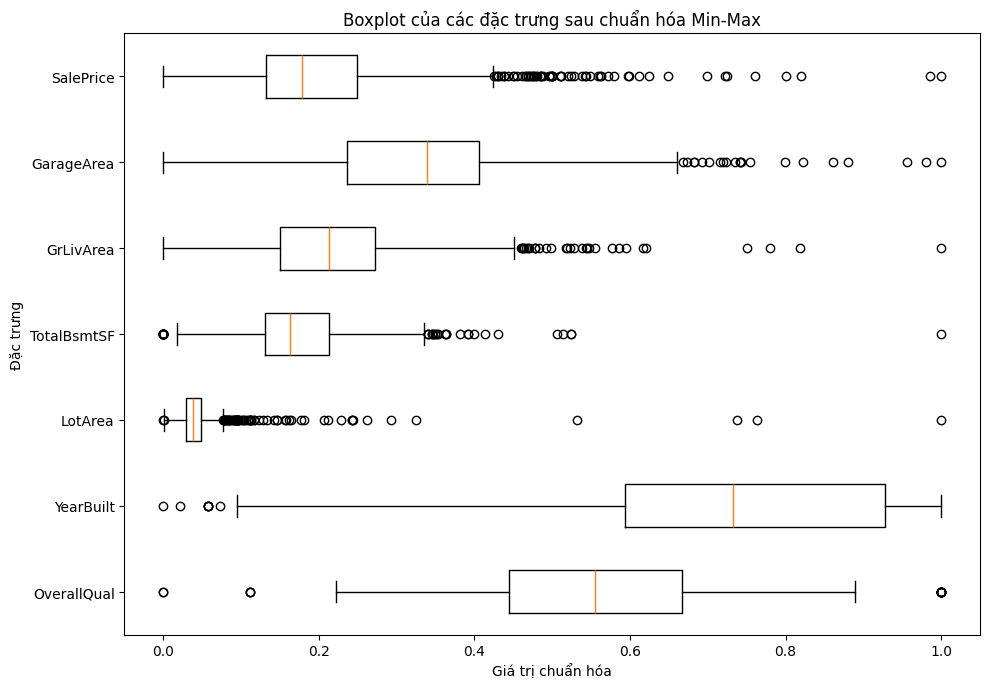

In [21]:
scaler = MinMaxScaler()
train_scaled = pd.DataFrame(scaler.fit_transform(train[features]), columns=features)

plt.figure(figsize=(10, 7))
plt.boxplot([train_scaled[c] for c in features], vert=False, tick_labels=features)
plt.title('Boxplot của các đặc trưng sau chuẩn hóa Min-Max')
plt.xlabel('Giá trị chuẩn hóa')
plt.ylabel('Đặc trưng')
plt.tight_layout()
plt.show()

Frequency.

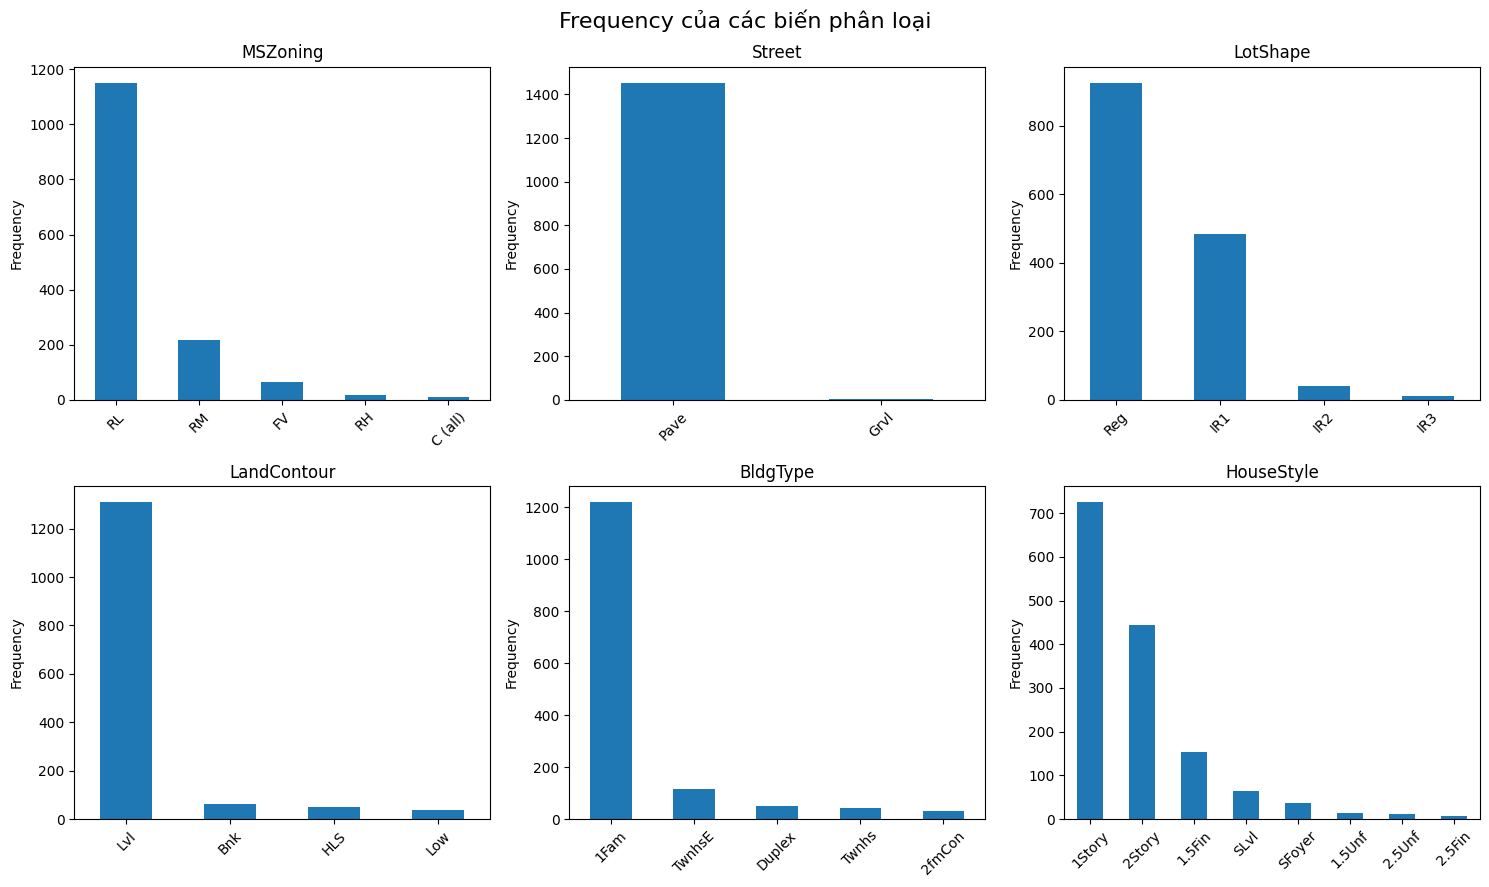

In [22]:
cat_freq = ['MSZoning', 'Street', 'LotShape', 'LandContour', 'BldgType', 'HouseStyle']
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, col in zip(axes.flatten(), cat_freq):
    train[col].value_counts().plot(kind='bar', ax=ax, rot=45)
    ax.set_title(col)
    ax.set_xlabel('')
    ax.set_ylabel('Frequency')
fig.suptitle('Frequency của các biến phân loại', fontsize=16)
plt.tight_layout()
plt.show()

Bar chart.

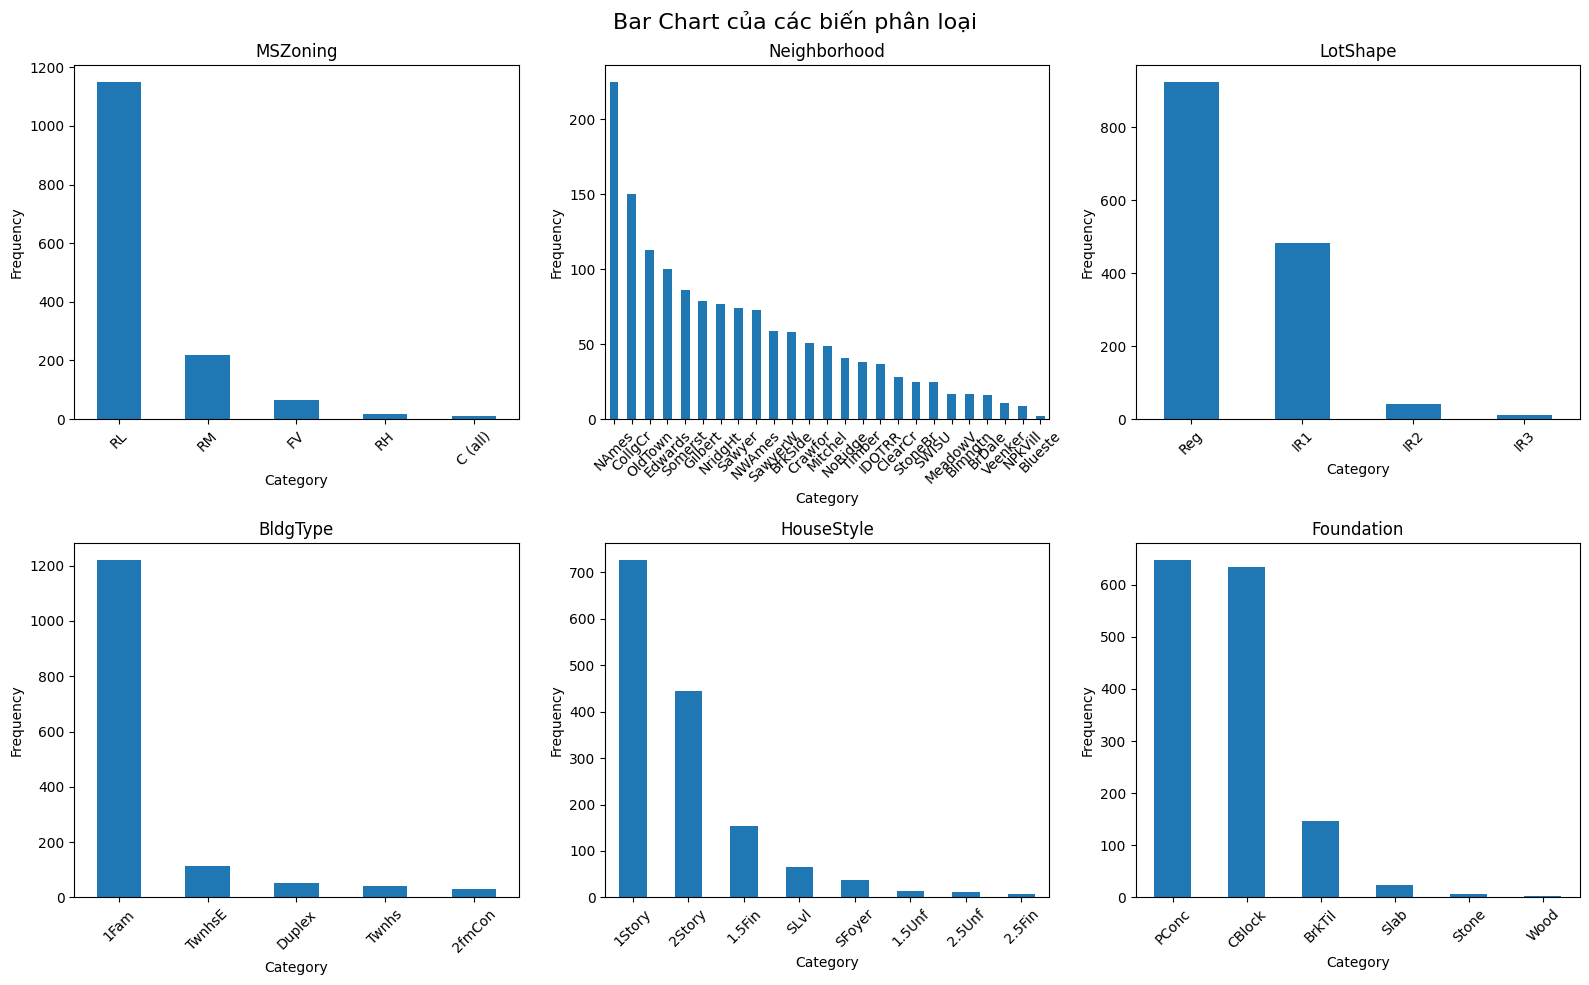

In [23]:
cat_bar = ['MSZoning', 'Neighborhood', 'LotShape', 'BldgType', 'HouseStyle', 'Foundation']
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, col in zip(axes.flatten(), cat_bar):
    train[col].value_counts().plot(kind='bar', ax=ax, rot=45)
    ax.set_title(col)
    ax.set_xlabel('Category')
    ax.set_ylabel('Frequency')
fig.suptitle('Bar Chart của các biến phân loại', fontsize=16)
plt.tight_layout()
plt.show()

## 4.2. Bivariate Analysis

### 4.2.1. Numerical vs Numerical

#### 4.2.1.1. Chọn cặp Numerical vs Numerical

In [24]:
pairs = ['GrLivArea', 'OverallQual', 'TotalBsmtSF', 'YearBuilt', 'GarageArea']
pd.DataFrame({'STT': range(1, 6), 'Biến X': pairs, 'Biến Y': 'SalePrice'})

,STT,Biến X,Biến Y
0,1,GrLivArea,SalePrice
1,2,OverallQual,SalePrice
2,3,TotalBsmtSF,SalePrice
3,4,YearBuilt,SalePrice
4,5,GarageArea,SalePrice


#### 4.2.1.2. Correlation

In [25]:
for col in pairs:
    print(f"{col} vs SalePrice: {train[col].corr(train['SalePrice']):.4f}")

GrLivArea vs SalePrice: 0.7086
OverallQual vs SalePrice: 0.7910
TotalBsmtSF vs SalePrice: 0.6136
YearBuilt vs SalePrice: 0.5229
GarageArea vs SalePrice: 0.6234


#### 4.2.1.3. Scatter Plot

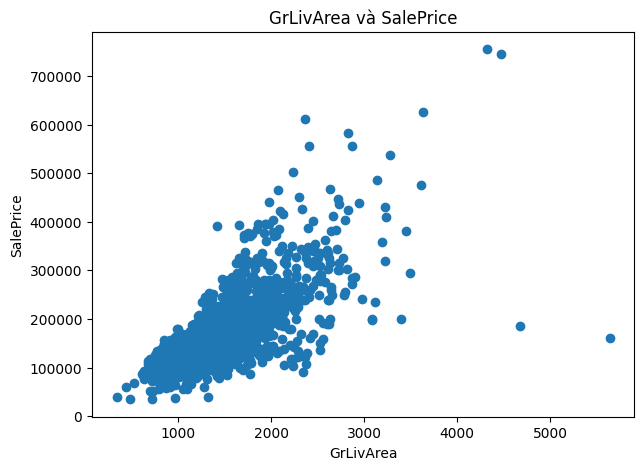

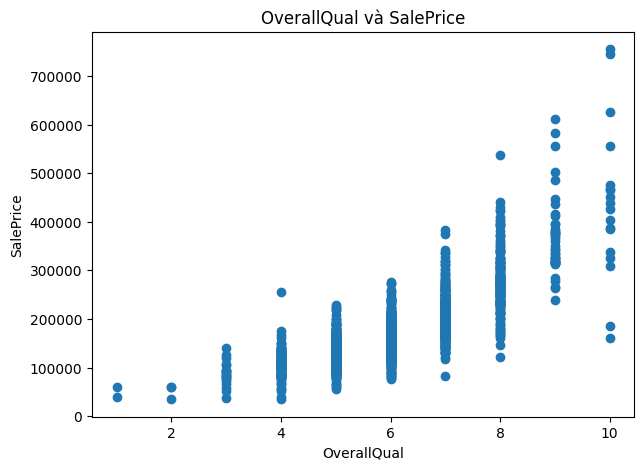

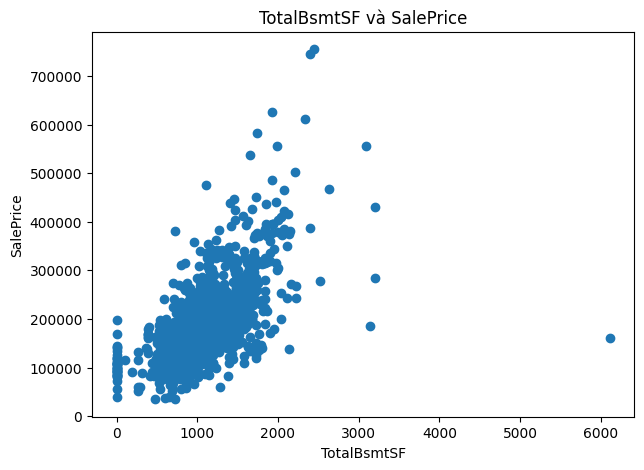

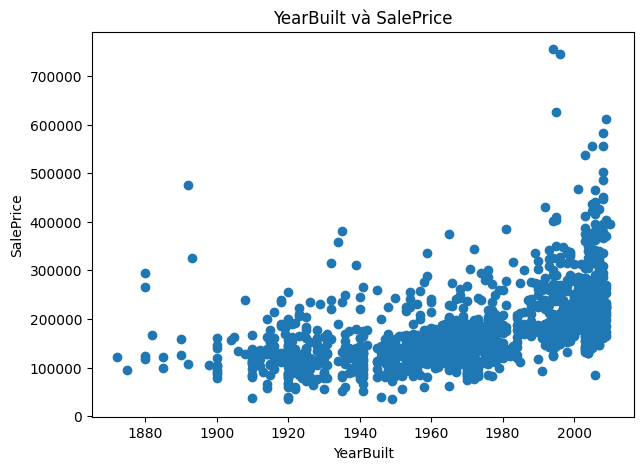

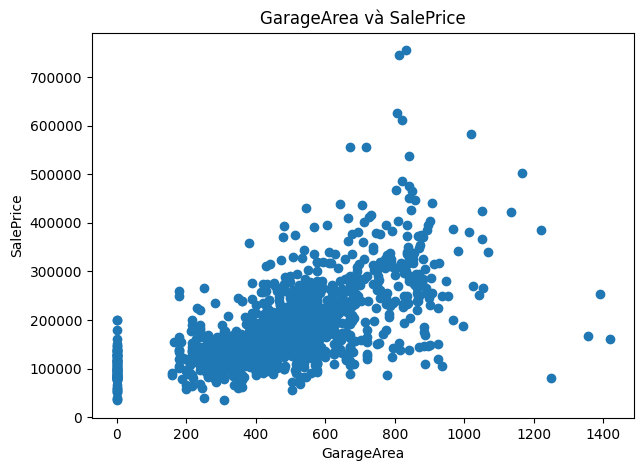

In [26]:
for col in pairs:
    plt.figure(figsize=(7, 5))
    plt.scatter(train[col], train['SalePrice'])
    plt.title(f'{col} và SalePrice')
    plt.xlabel(col)
    plt.ylabel('SalePrice')
    plt.show()

### 4.2.2. Numerical vs Categorical

#### 4.2.2.1. SalePrice vs OverallQual

In [27]:
train.groupby('OverallQual')['SalePrice'].agg(['count', 'mean', 'median', 'std', 'min', 'max']).round(2)

,count,mean,median,std,min,max
OverallQual,,,,,,
1,2,50150.00,50150.0,15344.22,39300,61000
2,3,51770.33,60000.0,14254.20,35311,60000
3,20,87473.75,86250.0,24688.57,37900,139600
4,116,108420.66,108000.0,29022.00,34900,256000
5,397,133523.35,133000.0,27107.33,55993,228950
6,374,161603.03,160000.0,36090.18,76000,277000
7,319,207716.42,200141.0,44466.26,82500,383970
8,168,274735.54,269750.0,63898.90,122000,538000
9,43,367513.02,345000.0,81278.17,239000,611657


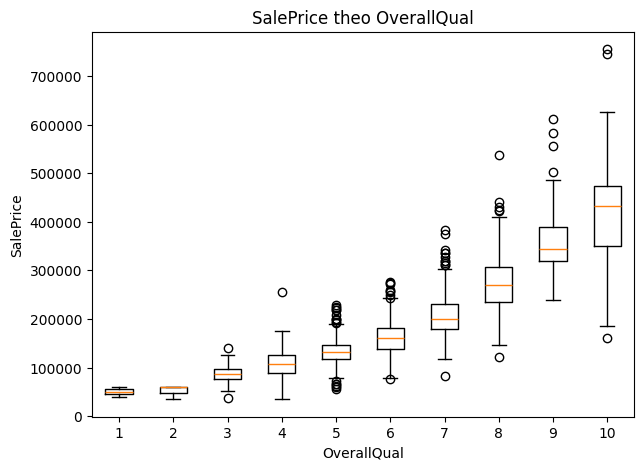

In [28]:
levels = sorted(train['OverallQual'].unique())
plt.figure(figsize=(7, 5))
plt.boxplot([train.loc[train['OverallQual'] == q, 'SalePrice'] for q in levels], tick_labels=levels)
plt.title('SalePrice theo OverallQual')
plt.xlabel('OverallQual')
plt.ylabel('SalePrice')
plt.show()

#### 4.2.2.2. SalePrice vs Neighborhood

In [29]:
train.groupby('Neighborhood')['SalePrice'].agg(['count', 'mean', 'median', 'std', 'min', 'max']).round(2)

,count,mean,median,std,min,max
Neighborhood,,,,,,
Blmngtn,17,194870.88,191000.0,30393.23,159895,264561
Blueste,2,137500.00,137500.0,19091.88,124000,151000
BrDale,16,104493.75,106000.0,14330.18,83000,125000
BrkSide,58,124834.05,124300.0,40348.69,39300,223500
ClearCr,28,212565.43,200250.0,50231.54,130000,328000
CollgCr,150,197965.77,197200.0,51403.67,110000,424870
Crawfor,51,210624.73,200624.0,68866.40,90350,392500
Edwards,100,128219.70,121750.0,43208.62,58500,320000
Gilbert,79,192854.51,181000.0,35986.78,141000,377500


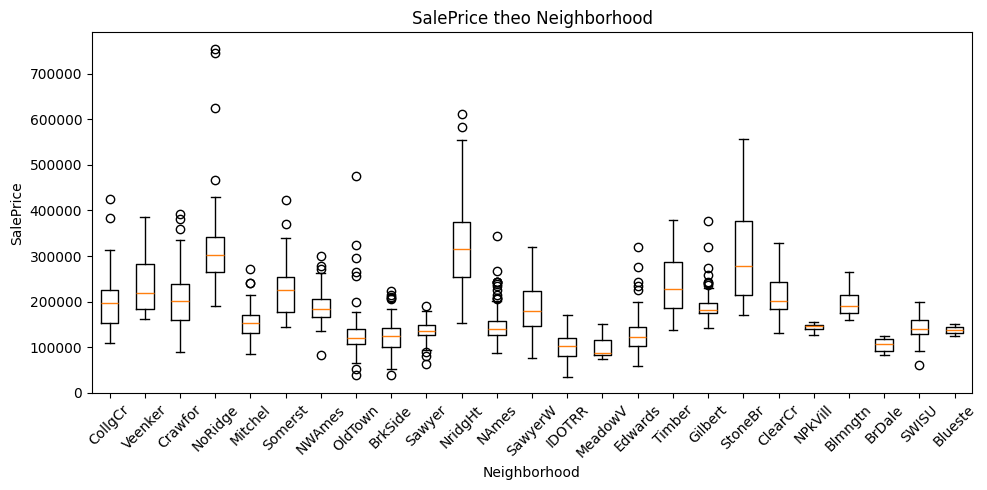

In [30]:
groups_nb = train['Neighborhood'].unique()
plt.figure(figsize=(10, 5))
plt.boxplot([train.loc[train['Neighborhood'] == g, 'SalePrice'] for g in groups_nb], tick_labels=groups_nb)
plt.xticks(rotation=45)
plt.title('SalePrice theo Neighborhood')
plt.xlabel('Neighborhood')
plt.ylabel('SalePrice')
plt.tight_layout()
plt.show()

#### 4.2.2.3. SalePrice theo HouseStyle

In [31]:
train.groupby('HouseStyle')['SalePrice'].agg(['count', 'mean', 'median', 'std', 'min', 'max']).round(2)

,count,mean,median,std,min,max
HouseStyle,,,,,,
1.5Fin,154,143116.74,132000.0,54277.94,37900,410000
1.5Unf,14,110150.00,111250.0,19036.47,76000,139400
1Story,726,175985.48,154750.0,77055.72,34900,611657
2.5Fin,8,220000.00,194000.0,118211.98,104000,475000
2.5Unf,11,157354.55,133900.0,63934.13,101000,325000
2Story,445,210051.76,190000.0,87339.21,40000,755000
SFoyer,37,135074.49,135960.0,30480.90,75500,206300
SLvl,65,166703.38,164500.0,38305.16,91000,345000


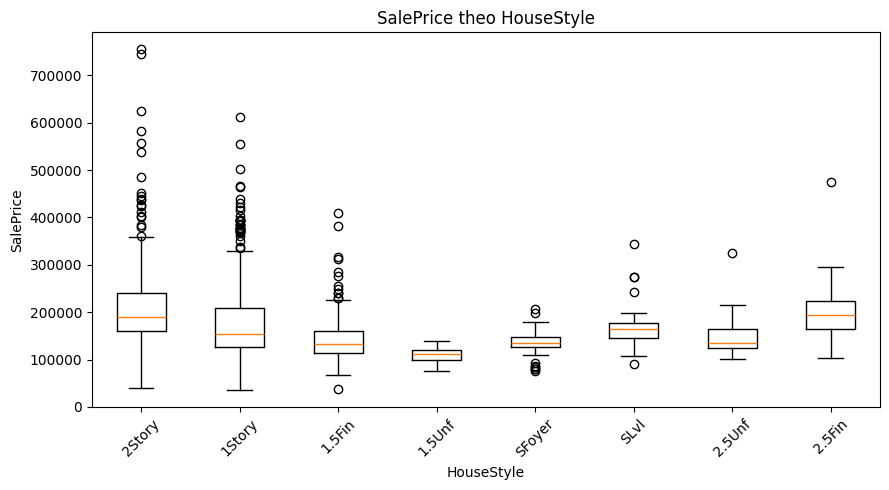

In [32]:
groups_hs = train['HouseStyle'].unique()
plt.figure(figsize=(9, 5))
plt.boxplot([train.loc[train['HouseStyle'] == g, 'SalePrice'] for g in groups_hs], tick_labels=groups_hs)
plt.xticks(rotation=45)
plt.title('SalePrice theo HouseStyle')
plt.xlabel('HouseStyle')
plt.ylabel('SalePrice')
plt.tight_layout()
plt.show()

#### 4.2.2.4. SalePrice vs GarageType

In [33]:
train.groupby('GarageType')['SalePrice'].agg(['count', 'mean', 'median', 'std', 'min', 'max']).round(2)

,count,mean,median,std,min,max
GarageType,,,,,,
2Types,6,151283.33,159000.0,34917.07,87000,186700
Attchd,870,202892.66,185000.0,77146.62,60000,755000
Basment,19,160570.68,148000.0,63967.28,55993,359100
BuiltIn,88,254751.74,227500.0,102230.85,91000,582933
CarPort,9,109962.11,108000.0,24638.18,82000,164900
Detchd,387,134091.16,129500.0,41391.55,35311,475000


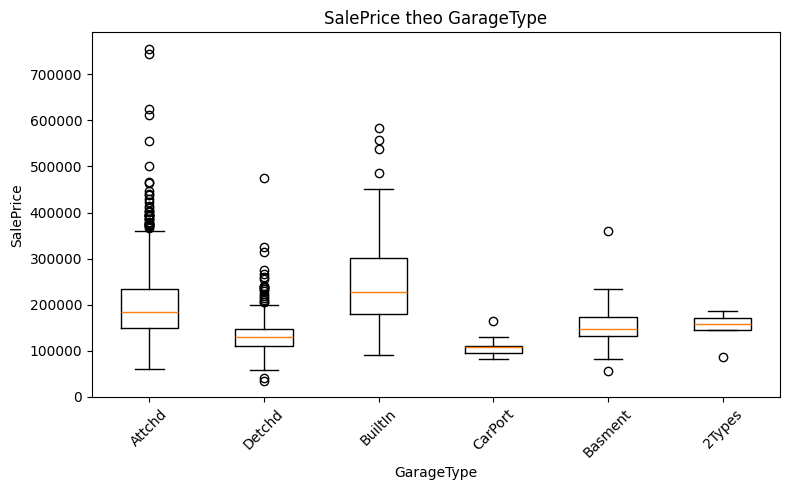

In [34]:
groups_gt = train['GarageType'].dropna().unique()
plt.figure(figsize=(8, 5))
plt.boxplot([train.loc[train['GarageType'] == g, 'SalePrice'] for g in groups_gt], tick_labels=groups_gt)
plt.xticks(rotation=45)
plt.title('SalePrice theo GarageType')
plt.xlabel('GarageType')
plt.ylabel('SalePrice')
plt.tight_layout()
plt.show()

### 4.2.3. Categorical vs Categorical

#### 4.2.3.1. HouseStyle × BldgType

Bảng thống kê Frequency.

In [35]:
ct_hb = pd.crosstab(train['HouseStyle'], train['BldgType'])
ct_hb

BldgType,1Fam,2fmCon,Duplex,Twnhs,TwnhsE
HouseStyle,,,,,
1.5Fin,142,8,4,0,0
1.5Unf,13,1,0,0,0
1Story,607,7,29,5,78
2.5Fin,7,1,0,0,0
2.5Unf,9,2,0,0,0
2Story,362,11,9,33,30
SFoyer,20,0,9,4,4
SLvl,60,1,1,1,2


Frequency theo phần trăm.

In [36]:
(pd.crosstab(train['HouseStyle'], train['BldgType'], normalize='index') * 100).round(2)

BldgType,1Fam,2fmCon,Duplex,Twnhs,TwnhsE
HouseStyle,,,,,
1.5Fin,92.21,5.19,2.60,0.00,0.00
1.5Unf,92.86,7.14,0.00,0.00,0.00
1Story,83.61,0.96,3.99,0.69,10.74
2.5Fin,87.50,12.50,0.00,0.00,0.00
2.5Unf,81.82,18.18,0.00,0.00,0.00
2Story,81.35,2.47,2.02,7.42,6.74
SFoyer,54.05,0.00,24.32,10.81,10.81
SLvl,92.31,1.54,1.54,1.54,3.08


Bar Chart.

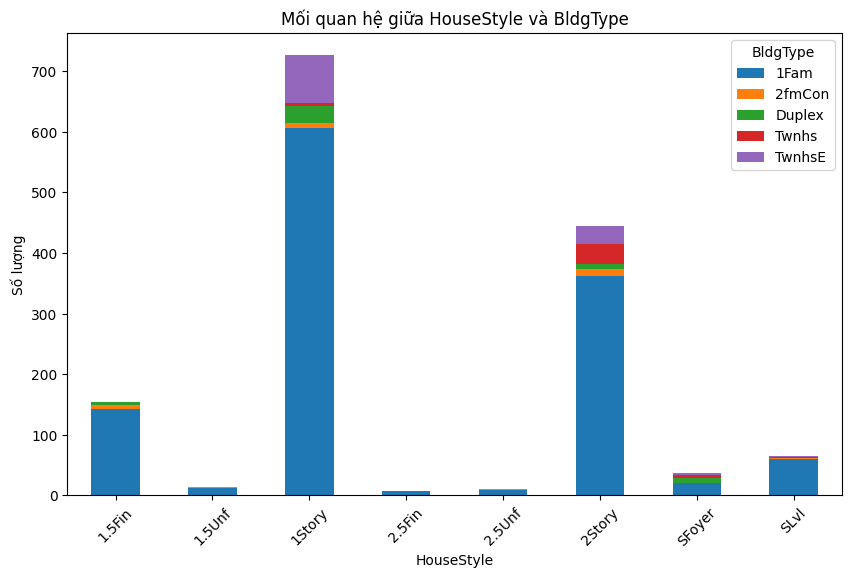

In [37]:
ct_hb.plot(kind='bar', stacked=True, figsize=(10, 6))
plt.title('Mối quan hệ giữa HouseStyle và BldgType')
plt.xlabel('HouseStyle')
plt.ylabel('Số lượng')
plt.xticks(rotation=45)
plt.show()

#### 4.2.3.2. GarageType × GarageFinish

Bảng thống kê Frequency.

In [38]:
ct_gg = pd.crosstab(train['GarageType'], train['GarageFinish'])
ct_gg

GarageFinish,Fin,RFn,Unf
GarageType,,,
2Types,1,2,3
Attchd,274,371,225
Basment,4,6,9
BuiltIn,59,24,5
CarPort,0,0,9
Detchd,14,19,354


Frequency theo phần trăm.

In [39]:
(pd.crosstab(train['GarageType'], train['GarageFinish'], normalize='index') * 100).round(2)

GarageFinish,Fin,RFn,Unf
GarageType,,,
2Types,16.67,33.33,50.00
Attchd,31.49,42.64,25.86
Basment,21.05,31.58,47.37
BuiltIn,67.05,27.27,5.68
CarPort,0.00,0.00,100.00
Detchd,3.62,4.91,91.47


Bar Chart.

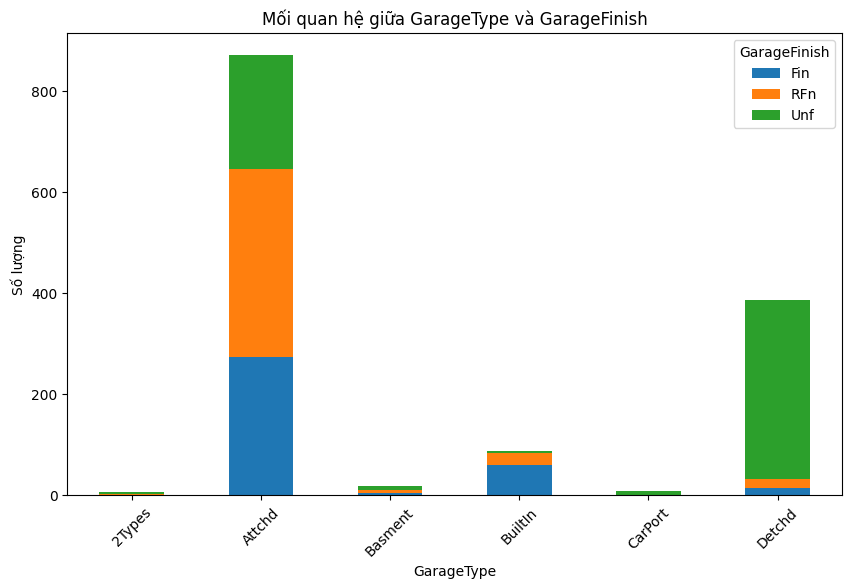

In [40]:
ct_gg.plot(kind='bar', stacked=True, figsize=(10, 6))
plt.title('Mối quan hệ giữa GarageType và GarageFinish')
plt.xlabel('GarageType')
plt.ylabel('Số lượng')
plt.xticks(rotation=45)
plt.show()

## 4.3. Multivariate Analysis

### 4.3.1. Ma trận tương quan

Bảng tương quan.

In [41]:
corr_matrix = train[cols_top].corr()
corr_matrix

,SalePrice,OverallQual,GrLivArea,GarageCars,GarageArea,TotalBsmtSF,1stFlrSF,FullBath,TotRmsAbvGrd,YearBuilt,YearRemodAdd
SalePrice,1.000000,0.790982,0.708624,0.640409,0.623431,0.613581,0.605852,0.560664,0.533723,0.522897,0.507101
OverallQual,0.790982,1.000000,0.593007,0.600671,0.562022,0.537808,0.476224,0.550600,0.427452,0.572323,0.550684
GrLivArea,0.708624,0.593007,1.000000,0.467247,0.468997,0.454868,0.566024,0.630012,0.825489,0.199010,0.287389
GarageCars,0.640409,0.600671,0.467247,1.000000,0.882475,0.434585,0.439317,0.469672,0.362289,0.537850,0.420622
GarageArea,0.623431,0.562022,0.468997,0.882475,1.000000,0.486665,0.489782,0.405656,0.337822,0.478954,0.371600
TotalBsmtSF,0.613581,0.537808,0.454868,0.434585,0.486665,1.000000,0.819530,0.323722,0.285573,0.391452,0.291066
1stFlrSF,0.605852,0.476224,0.566024,0.439317,0.489782,0.819530,1.000000,0.380637,0.409516,0.281986,0.240379
FullBath,0.560664,0.550600,0.630012,0.469672,0.405656,0.323722,0.380637,1.000000,0.554784,0.468271,0.439046
TotRmsAbvGrd,0.533723,0.427452,0.825489,0.362289,0.337822,0.285573,0.409516,0.554784,1.000000,0.095589,0.191740
YearBuilt,0.522897,0.572323,0.199010,0.537850,0.478954,0.391452,0.281986,0.468271,0.095589,1.000000,0.592855


HeatBox.

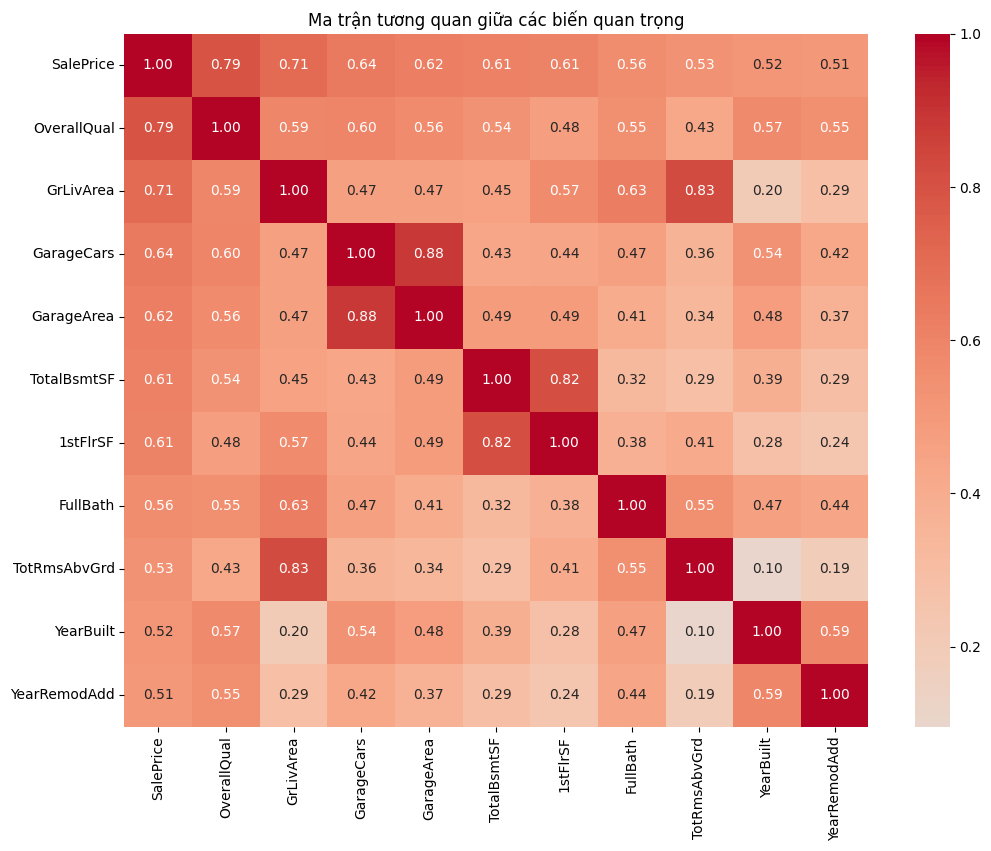

In [42]:
plt.figure(figsize=(12, 9))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Ma trận tương quan giữa các biến quan trọng')
plt.show()

### 4.3.2. Scatter plot đa biến

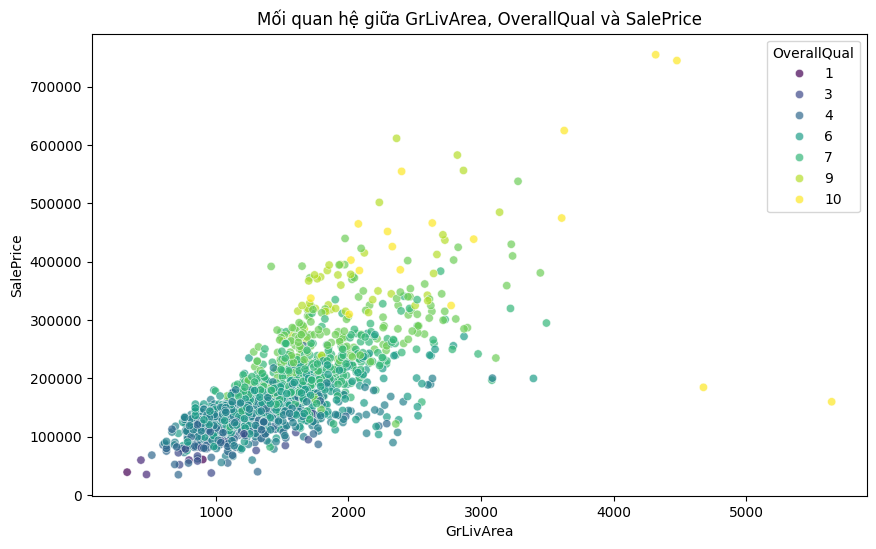

In [43]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=train, x='GrLivArea', y='SalePrice', hue='OverallQual', palette='viridis', alpha=0.7)
plt.title('Mối quan hệ giữa GrLivArea, OverallQual và SalePrice')
plt.show()

### 4.3.3. Phân tích tương tác giữa các biến

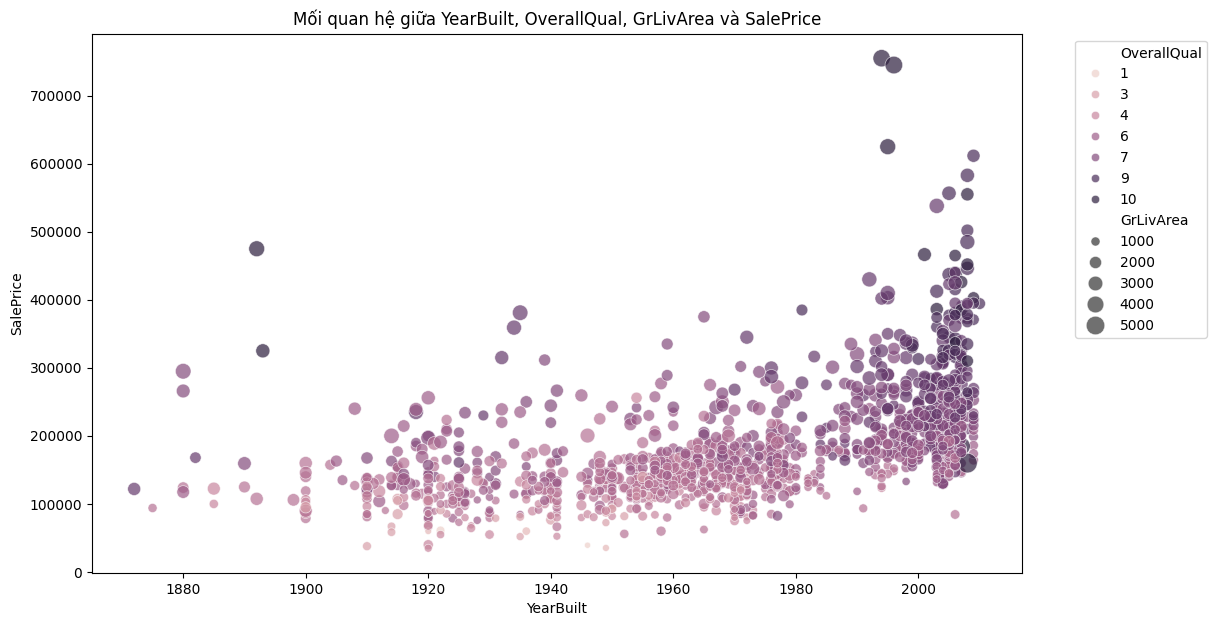

In [44]:
plt.figure(figsize=(12, 7))
sns.scatterplot(data=train, x='YearBuilt', y='SalePrice', hue='OverallQual', size='GrLivArea',
                sizes=(20, 200), alpha=0.7)
plt.title('Mối quan hệ giữa YearBuilt, OverallQual, GrLivArea và SalePrice')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

# 5. XÁC ĐỊNH MẪU BẤT THƯỜNG

## 5.1. IQR của SalePrice

In [45]:
q1_sp, q3_sp = train['SalePrice'].quantile([0.25, 0.75])
iqr_sp = q3_sp - q1_sp
lower_sp = q1_sp - 1.5 * iqr_sp
upper_sp = q3_sp + 1.5 * iqr_sp
outliers_sp = train[(train['SalePrice'] < lower_sp) | (train['SalePrice'] > upper_sp)]
print("Q1:", q1_sp, "Q3:", q3_sp, "IQR:", iqr_sp)
print("Khoảng bình thường:", [lower_sp, upper_sp])
print("Number of outliers:", len(outliers_sp))
print("Số mẫu cao hơn ngưỡng trên:", (outliers_sp['SalePrice'] > upper_sp).sum())

Q1: 129975.0 Q3: 214000.0 IQR: 84025.0
Khoảng bình thường: [3937.5, 340037.5]
Number of outliers: 61
Số mẫu cao hơn ngưỡng trên: 61


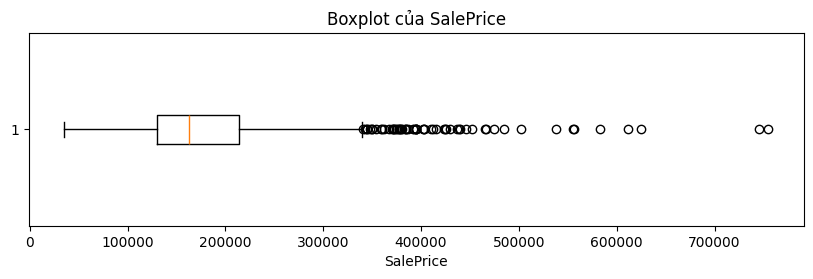

In [46]:
plt.figure(figsize=(10, 2.5))
plt.boxplot(train['SalePrice'], vert=False)
plt.title('Boxplot của SalePrice')
plt.xlabel('SalePrice')
plt.show()

In [47]:
outliers_sp[['Id', 'SalePrice', 'GrLivArea', 'OverallQual', 'Neighborhood']].sort_values('SalePrice', ascending=False).head(10)

,Id,SalePrice,GrLivArea,OverallQual,Neighborhood
691,692,755000,4316,10,NoRidge
1182,1183,745000,4476,10,NoRidge
1169,1170,625000,3627,10,NoRidge
898,899,611657,2364,9,NridgHt
803,804,582933,2822,9,NridgHt
1046,1047,556581,2868,9,StoneBr
440,441,555000,2402,10,NridgHt
769,770,538000,3279,8,StoneBr
178,179,501837,2234,9,StoneBr
798,799,485000,3140,9,NridgHt


## 5.3. Scatter Plot GrLivArea và SalePrice

In [48]:
q1_gl, q3_gl = train['GrLivArea'].quantile([0.25, 0.75])
iqr_gl = q3_gl - q1_gl
lower_gl = q1_gl - 1.5 * iqr_gl
upper_gl = q3_gl + 1.5 * iqr_gl
outliers_gl = train[(train['GrLivArea'] < lower_gl) | (train['GrLivArea'] > upper_gl)]
print("Q1:", q1_gl, "Q3:", q3_gl, "IQR:", iqr_gl)
print("Khoảng bình thường:", [lower_gl, upper_gl])
print("Number of outliers:", len(outliers_gl))

Q1: 1129.5 Q3: 1776.75 IQR: 647.25
Khoảng bình thường: [158.625, 2747.625]
Number of outliers: 31


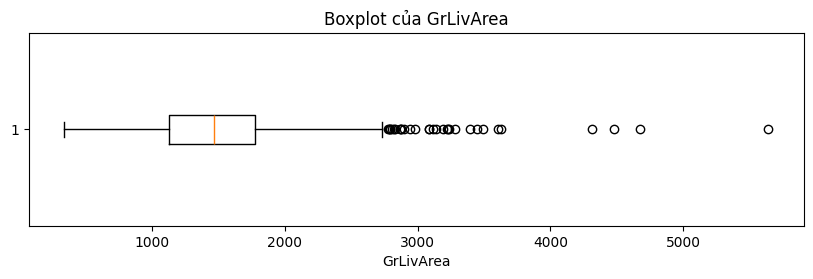

In [49]:
plt.figure(figsize=(10, 2.5))
plt.boxplot(train['GrLivArea'], vert=False)
plt.title('Boxplot của GrLivArea')
plt.xlabel('GrLivArea')
plt.show()

## 5.4. Z-score của SalePrice

In [50]:
z_sp = np.abs(stats.zscore(train['SalePrice']))
outliers_z = train[z_sp > 3]
print("Number of outliers Z-score:", len(outliers_z))
print("Number of outliers IQR:", len(outliers_sp))

Number of outliers Z-score: 22
Number of outliers IQR: 61


# 6. OUTLIER DETECTION

## 6.1. Phát hiện Outlier bằng IQR

In [51]:
outlier_cols = ['SalePrice', 'GrLivArea', 'LotArea', 'TotalBsmtSF', '1stFlrSF', 'GarageArea']
rows = []
for col in outlier_cols:
    q1, q3 = train[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((train[col] < lower) | (train[col] > upper)).sum()
    rows.append([col, q1, q3, iqr, lower, upper, n_out])
iqr_table = pd.DataFrame(rows, columns=['Feature', 'Q1', 'Q3', 'IQR', 'Lower Bound', 'Upper Bound', 'Số lượng Outlier'])
iqr_table

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Số lượng Outlier
0,SalePrice,129975.00,214000.00,84025.00,3937.500,340037.500,61
1,GrLivArea,1129.50,1776.75,647.25,158.625,2747.625,31
2,LotArea,7553.50,11601.50,4048.00,1481.500,17673.500,69
3,TotalBsmtSF,795.75,1298.25,502.50,42.000,2052.000,61
4,1stFlrSF,882.00,1391.25,509.25,118.125,2155.125,20
5,GarageArea,334.50,576.00,241.50,-27.750,938.250,21


## 6.2. Phát hiện Outlier bằng Z-Score

In [52]:
rows = []
for col in outlier_cols:
    z = np.abs(stats.zscore(train[col]))
    rows.append([col, (z > 3).sum()])
pd.DataFrame(rows, columns=['Feature', 'Số lượng Outlier'])

,Feature,Số lượng Outlier
0,SalePrice,22
1,GrLivArea,16
2,LotArea,13
3,TotalBsmtSF,10
4,1stFlrSF,12
5,GarageArea,7


# 7. Preprocessing data

In [53]:
train_raw = train.copy()
all_data = pd.concat([train.drop(columns='SalePrice'), test], ignore_index=True)
n_train = len(train)
print("Train:", train.shape, "Test:", test.shape)

Train: (1460, 81) Test: (1459, 80)


## 7.1 Xử lý dữ liệu thiếu

In [54]:
print("Train thiếu:", train.isnull().sum().sum(), "ô ở", (train.isnull().sum() > 0).sum(), "cột")
print("Test thiếu ở", (test.isnull().sum() > 0).sum(), "cột")

none_cols = ['PoolQC', 'Alley', 'Fence', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
             'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'MasVnrType', 'MiscFeature']
zero_cols = ['GarageArea', 'GarageCars', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF',
             'BsmtFullBath', 'BsmtHalfBath', 'MasVnrArea']
mode_cols = ['MSZoning', 'Electrical', 'KitchenQual', 'Exterior1st', 'Exterior2nd', 'SaleType', 'Functional',
             'Utilities']

all_data[none_cols] = all_data[none_cols].fillna('None')
all_data[zero_cols] = all_data[zero_cols].fillna(0)
all_data['LotFrontage'] = all_data.groupby('Neighborhood')['LotFrontage'].transform(lambda s: s.fillna(s.median()))
all_data['GarageYrBlt'] = all_data['GarageYrBlt'].fillna(all_data['YearBuilt'])
for col in mode_cols:
    all_data[col] = all_data[col].fillna(all_data[col].mode()[0])

print("Số ô thiếu ở train sau xử lý:", all_data.iloc[:n_train].isnull().sum().sum())
print("Số ô thiếu ở test sau xử lý:", all_data.iloc[n_train:].isnull().sum().sum())

Train thiếu: 7829 ô ở 19 cột
Test thiếu ở 33 cột
Số ô thiếu ở train sau xử lý: 0
Số ô thiếu ở test sau xử lý: 0


## 7.2 Xử lý giá trị bất thường

In [55]:
mask = all_data['GarageYrBlt'] > all_data['YrSold']
print("GarageYrBlt > YrSold:", mask.sum())
all_data.loc[mask, 'GarageYrBlt'] = all_data.loc[mask, 'YearBuilt']

mask = all_data['YearRemodAdd'] < all_data['YearBuilt']
print("YearRemodAdd < YearBuilt:", mask.sum())
all_data.loc[mask, 'YearRemodAdd'] = all_data.loc[mask, 'YearBuilt']

mask = all_data['YrSold'] < all_data['YearBuilt']
print("YrSold < YearBuilt:", mask.sum())
all_data.loc[mask, 'YrSold'] = all_data.loc[mask, 'YearBuilt']

print("YrSold < YearRemodAdd giữ nguyên:", (all_data['YrSold'] < all_data['YearRemodAdd']).sum())
print("Giá trị âm:", (all_data.select_dtypes('number') < 0).sum().sum())

GarageYrBlt > YrSold: 2
YearRemodAdd < YearBuilt: 1
YrSold < YearBuilt: 1
YrSold < YearRemodAdd giữ nguyên: 3
Giá trị âm: 0


## 7.3 Xử lý Outlier

In [56]:
outlier_idx = train.index[(train['GrLivArea'] > 4000) & (train['SalePrice'] < 300000)]
print("Số điểm ngoại lai bị loại:", len(outlier_idx))
train = train.drop(index=outlier_idx)
all_data = all_data.drop(index=outlier_idx).reset_index(drop=True)
n_train = len(train)
y_log = np.log1p(train['SalePrice']).reset_index(drop=True)
print(all_data.shape, n_train)

Số điểm ngoại lai bị loại: 2
(2917, 80) 1458


Capping theo IQR.

In [57]:
area_cols = continuous
n_capped = {}
for col in area_cols:
    q1, q3 = all_data.iloc[:n_train][col].quantile([0.25, 0.75])
    iqr = q3 - q1
    if iqr == 0:
        lower, upper = -np.inf, all_data.iloc[:n_train][col].quantile(0.995)
    else:
        lower, upper = q1 - 3 * iqr, q3 + 3 * iqr
    n_capped[col] = ((all_data[col] < lower) | (all_data[col] > upper)).sum()
    all_data[col] = all_data[col].clip(lower=lower, upper=upper)
pd.Series(n_capped).sort_values(ascending=False).head(5)

MasVnrArea     54
LotArea        51
OpenPorchSF    34
LotFrontage    19
MiscVal        19
dtype: int64

Feature mới.

In [58]:
all_data['TotalSF'] = all_data['TotalBsmtSF'] + all_data['1stFlrSF'] + all_data['2ndFlrSF']
all_data['TotalBath'] = (all_data['FullBath'] + 0.5 * all_data['HalfBath']
                         + all_data['BsmtFullBath'] + 0.5 * all_data['BsmtHalfBath'])
all_data['HouseAge'] = 2010 - all_data['YearBuilt']
all_data['HasPool'] = (all_data['PoolArea'] > 0).astype(int)
all_data['HasGarage'] = (all_data['GarageArea'] > 0).astype(int)
all_data['HasBsmt'] = (all_data['TotalBsmtSF'] > 0).astype(int)
all_data['HasFireplace'] = (all_data['Fireplaces'] > 0).astype(int)

Giảm độ lệch bằng log1p.

In [59]:
skew_cols = area_cols + ['TotalSF']
skewness = all_data.iloc[:n_train][skew_cols].skew()
skewed = skewness[skewness.abs() > 0.75].index
print("Số biến lệch:", len(skewed))
print(list(skewed))
all_data[skewed] = np.log1p(all_data[skewed])
print("Skew của SalePrice sau log1p:", round(y_log.skew(), 2))

Số biến lệch: 16
['LotArea', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'MiscVal', 'TotalSF']
Skew của SalePrice sau log1p: 0.12


## 7.4 Xử lý Categorical Data

In [60]:
qual = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}
for col in ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC', 'KitchenQual', 'FireplaceQu',
            'GarageQual', 'GarageCond', 'PoolQC']:
    all_data[col] = all_data[col].map(qual)

fin = {'None': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3, 'BLQ': 4, 'ALQ': 5, 'GLQ': 6}
all_data['BsmtFinType1'] = all_data['BsmtFinType1'].map(fin)
all_data['BsmtFinType2'] = all_data['BsmtFinType2'].map(fin)
all_data['BsmtExposure'] = all_data['BsmtExposure'].map({'None': 0, 'No': 1, 'Mn': 2, 'Av': 3, 'Gd': 4})
all_data['GarageFinish'] = all_data['GarageFinish'].map({'None': 0, 'Unf': 1, 'RFn': 2, 'Fin': 3})
all_data['Fence'] = all_data['Fence'].map({'None': 0, 'MnWw': 1, 'GdWo': 2, 'MnPrv': 3, 'GdPrv': 4})
all_data['LotShape'] = all_data['LotShape'].map({'IR3': 0, 'IR2': 1, 'IR1': 2, 'Reg': 3})
all_data['LandSlope'] = all_data['LandSlope'].map({'Sev': 0, 'Mod': 1, 'Gtl': 2})
all_data['Functional'] = all_data['Functional'].map(
    {'Sal': 0, 'Sev': 1, 'Maj2': 2, 'Maj1': 3, 'Mod': 4, 'Min2': 5, 'Min1': 6, 'Typ': 7})
all_data['PavedDrive'] = all_data['PavedDrive'].map({'N': 0, 'P': 1, 'Y': 2})
all_data['Utilities'] = all_data['Utilities'].map({'ELO': 0, 'NoSeWa': 1, 'NoSewr': 2, 'AllPub': 3})
all_data['CentralAir'] = all_data['CentralAir'].map({'N': 0, 'Y': 1})

for col in ['MSSubClass', 'MoSold', 'YrSold']:
    all_data[col] = all_data[col].astype(str)

nominal_cols = [c for c in all_data.columns if not pd.api.types.is_numeric_dtype(all_data[c])]
print("Số cột nominal:", len(nominal_cols))
all_data = pd.get_dummies(all_data, columns=nominal_cols, drop_first=True, dtype=int)

train_processed = all_data.iloc[:n_train].copy()
train_processed['SalePrice_log'] = y_log.values
test_processed = all_data.iloc[n_train:].reset_index(drop=True)

print("Train:", train_processed.drop(columns=['Id', 'SalePrice_log']).shape)
print("Test:", test_processed.drop(columns='Id').shape)
print("Missing:", train_processed.isnull().sum().sum(), test_processed.isnull().sum().sum())
print("Cột dạng chuỗi:", train_processed.select_dtypes(exclude='number').shape[1])

train_processed.to_csv('train_processed.csv', index=False)
test_processed.to_csv('test_processed.csv', index=False)

Số cột nominal: 25
Train: (1458, 235)
Test: (1459, 235)


Missing: 0 0
Cột dạng chuỗi: 0


# 8. SO SÁNH TRƯỚC VÀ SAU PREPROCESSING

## 8.1 So sánh dữ liệu

In [61]:
X_after = train_processed.drop(columns=['Id', 'SalePrice_log'])
num_before = train_raw.select_dtypes('number').drop(columns=['Id', 'SalePrice'])
multi_val = [c for c in X_after.columns if X_after[c].nunique() > 2]

def count_iqr_outliers(df):
    total = 0
    for col in area_cols:
        q1, q3 = df[col].quantile([0.25, 0.75])
        iqr = q3 - q1
        total += ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    return total

compare = pd.DataFrame({
    'Chỉ số train': ['Kích thước', 'Số ô dữ liệu thiếu', 'Số cột có dữ liệu thiếu', 'Số cột dạng chuỗi',
                     'Độ lệch của SalePrice', 'Độ lệch trung bình các biến số', 'Outlier theo 1.5 IQR'],
    'Trước': [f'{train_raw.shape[0]} x {train_raw.shape[1]}', train_raw.isnull().sum().sum(),
              (train_raw.isnull().sum() > 0).sum(), train_raw.select_dtypes(exclude='number').shape[1],
              round(train_raw['SalePrice'].skew(), 2), round(num_before.skew().abs().mean(), 2),
              count_iqr_outliers(train_raw)],
    'Sau': [f'{train_processed.shape[0]} x {X_after.shape[1]}', train_processed.isnull().sum().sum(),
            (train_processed.isnull().sum() > 0).sum(), train_processed.select_dtypes(exclude='number').shape[1],
            round(y_log.skew(), 2), round(X_after[multi_val].skew().abs().mean(), 2),
            count_iqr_outliers(X_after)]})
compare

,Chỉ số train,Trước,Sau
0,Kích thước,1460 x 81,1458 x 235
1,Số ô dữ liệu thiếu,7829,0
2,Số cột có dữ liệu thiếu,19,0
3,Số cột dạng chuỗi,43,0
4,Độ lệch của SalePrice,1.88,0.12
5,Độ lệch trung bình các biến số,3.2,1.9
6,Outlier theo 1.5 IQR,1133,1030


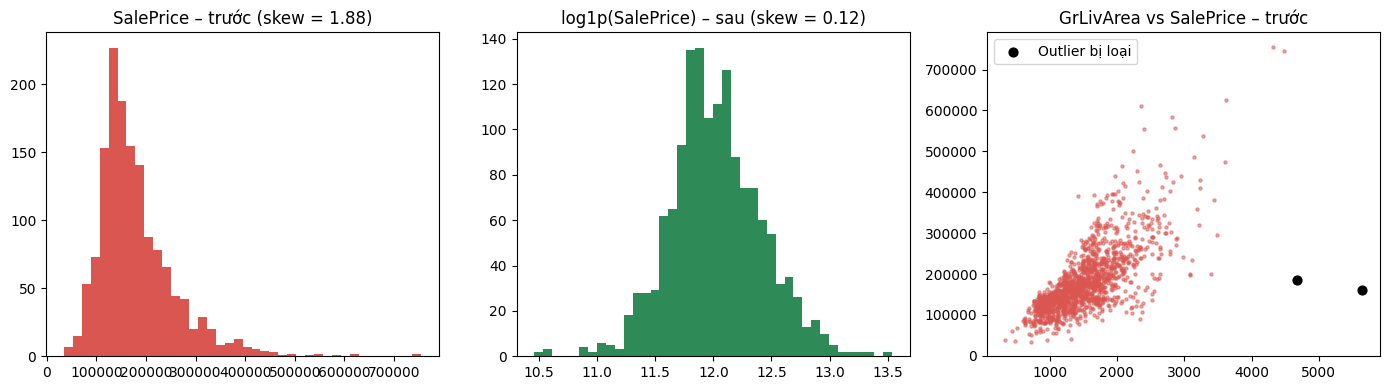

In [62]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].hist(train_raw['SalePrice'], bins=40, color='#DA5650')
axes[0].set_title(f"SalePrice – trước (skew = {train_raw['SalePrice'].skew():.2f})")
axes[1].hist(y_log, bins=40, color='#2E8B57')
axes[1].set_title(f'log1p(SalePrice) – sau (skew = {y_log.skew():.2f})')
axes[2].scatter(train_raw['GrLivArea'], train_raw['SalePrice'], s=5, alpha=0.5, color='#DA5650')
axes[2].scatter(train_raw.loc[outlier_idx, 'GrLivArea'], train_raw.loc[outlier_idx, 'SalePrice'],
                s=40, color='black', label='Outlier bị loại')
axes[2].set_title('GrLivArea vs SalePrice – trước')
axes[2].legend()
plt.tight_layout()
plt.show()

## 8.2 So sánh hiệu năng mô hình

In [63]:
X_before = train_raw.drop(columns=['Id', 'SalePrice']).select_dtypes('number')
X_before = X_before.fillna(X_before.median())
y_before = np.log1p(train_raw['SalePrice'])

kf = KFold(n_splits=5, shuffle=True, random_state=42)
models = {'Ridge': make_pipeline(StandardScaler(), Ridge(alpha=10)),
          'Random Forest': RandomForestRegressor(n_estimators=500, random_state=42, n_jobs=-1)}

rows = []
for name, model in models.items():
    rmse_before = -cross_val_score(model, X_before, y_before, cv=kf, scoring='neg_root_mean_squared_error').mean()
    rmse_after = -cross_val_score(model, X_after, y_log, cv=kf, scoring='neg_root_mean_squared_error').mean()
    rows.append([name, rmse_before, rmse_after, (rmse_before - rmse_after) / rmse_before * 100])
pd.DataFrame(rows, columns=['Mô hình', 'RMSE trước', 'RMSE sau', 'Cải thiện %']).round(4)

,Mô hình,RMSE trước,RMSE sau,Cải thiện %
0,Ridge,0.1596,0.1266,20.6745
1,Random Forest,0.1472,0.1366,7.1879


## 8.3 Nhận xét

- Dữ liệu thiếu và dữ liệu dạng chuỗi được xử lý hoàn toàn, giữ thông tin không có tính năng thay vì xóa dòng hoặc cột.
- Độ lệch của biến mục tiêu giảm mạnh sau log1p, các biến diện tích cũng bớt lệch.
- Sai số dự đoán giảm ở cả hai mô hình, Ridge cải thiện nhiều hơn Random Forest vì mô hình tuyến tính nhạy với độ lệch và outlier.

# Giả định khi tái dựng

Báo cáo không nêu các thông tin sau nên notebook dùng giá trị tái dựng:

- KFold shuffle với random_state=42, Ridge alpha=10 có StandardScaler, Random Forest 500 cây với random_state=42.
- HouseAge tính bằng 2010 trừ YearBuilt, khớp với train_processed.csv đi kèm, khác với công thức YrSold trừ YearBuilt trong báo cáo.
- Dòng YrSold nhỏ hơn YearBuilt được gán YrSold bằng YearBuilt.
- Thứ tự mã hóa ordinal theo quy ước None, Po, Fa, TA, Gd, Ex và thang chuẩn của data_description.txt cho các biến còn lại.
- Capping dùng 3 IQR tính từ train, riêng cột có IQR bằng 0 dùng phân vị 99.5%. HasPool tạo sau capping nên toàn bằng 0.
- Mục 4.2.2.4 trong báo cáo chèn nhầm bảng OverallQual, notebook tính bảng GarageType. Mục 5.3 trong báo cáo ghi Scatter Plot nhưng nội dung là Boxplot IQR của GrLivArea.
- Kết quả RMSE của Random Forest có thể lệch nhẹ so với báo cáo do báo cáo không nêu số cây và random_state.